In [2]:
import numpy as np
import matplotlib.pyplot as plt

def poly_kernel(X, Z, C=0, d=2):
    return (X @ Z.T + C) ** d

def make_poly_kernel(C=0, d=2):
    return lambda X, Z: poly_kernel(X, Z, C, d)

def rbf_kernel(X, Z, sigma=1.0):
    sq = (X**2).sum(1)[:, None] + (Z**2).sum(1)[None, :] - 2 * X @ Z.T
    return np.exp(-sq / (2 * sigma**2))

def make_rbf_kernel(sigma=1.0):
    return lambda X, Z: rbf_kernel(X, Z, sigma)


class KernelTrick:
    def __init__(self, kernel_fn, learning_rate=0.1, epochs=500):
        self.kernel_fn = kernel_fn
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.beta = None
        self.X_train = None
        self.loss_history = []

    def kernel_matrix(self, X, Z):
        return self.kernel_fn(X, Z)

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        n = X.shape[0]
        self.X_train = X

        K = self.kernel_matrix(X, X)
        lam_max = np.linalg.eigvalsh(K).max()
        lr = min(self.learning_rate, 1.0 / lam_max)   # 발산 방지

        self.beta = np.zeros(n)
        self.loss_history = []
        for _ in range(self.epochs):
            error = y - K @ self.beta
            self.beta = self.beta + lr * error
            self.loss_history.append(0.5 * np.mean(error ** 2))
        return self

    def predict(self, X_new):
        X_new = np.asarray(X_new, dtype=float)
        K_new = self.kernel_matrix(X_new, self.X_train)
        
        #예측값 theta.T 시그마(x)

        return K_new @ self.beta

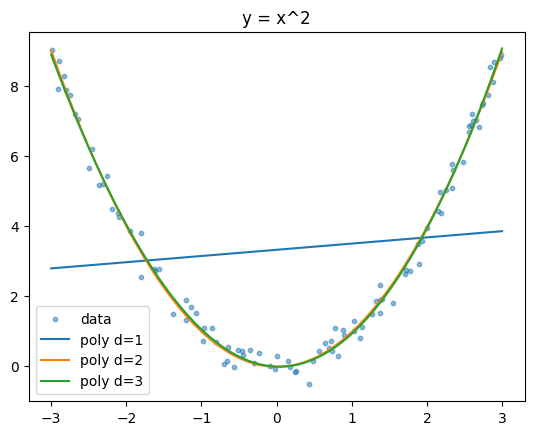

In [3]:
rng = np.random.default_rng(0)

X = rng.uniform(-3, 3, size=(100, 1))
#X^2 + 0.3(random) 2차 함수형태의 데이터
y = X[:, 0]**2 + 0.3 * rng.standard_normal(100)

X_line = np.linspace(-3, 3, 300).reshape(-1, 1)

plt.scatter(X, y, s=10, alpha=0.5, label="data")

for d in [1, 2, 3]:
    model = KernelTrick(make_poly_kernel(C=1, d=d), epochs=5000)
    model.fit(X, y)
    plt.plot(X_line, model.predict(X_line), label=f"poly d={d}")
    
plt.legend(); plt.title("y = x^2"); plt.show()



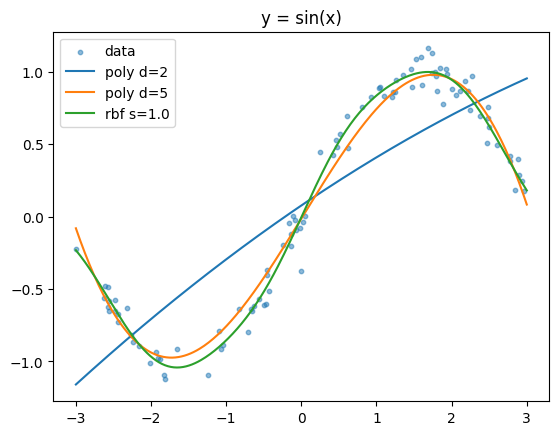

In [4]:
X = rng.uniform(-3, 3, size=(100, 1))
y = np.sin(X[:, 0]) + 0.1 * rng.standard_normal(100)

plt.scatter(X, y, s=10, alpha=0.5, label="data")
for name, kfn in [("poly d=2", make_poly_kernel(1, 2)),
                ("poly d=5", make_poly_kernel(1, 5)),
                ("rbf s=1.0", make_rbf_kernel(1.0))]:
    model = KernelTrick(kfn, epochs=20000)
    model.fit(X, y)
    plt.plot(X_line, model.predict(X_line), label=name)
plt.legend(); plt.title("y = sin(x)"); plt.show()

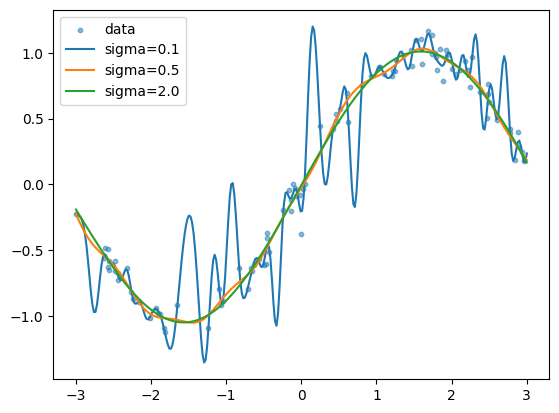

In [5]:
plt.scatter(X, y, s=10, alpha=0.5, label="data")
for s in [0.1, 0.5, 2.0]:
    model = KernelTrick(make_rbf_kernel(s), epochs=20000)
    model.fit(X, y)
    plt.plot(X_line, model.predict(X_line), label=f"sigma={s}")
plt.legend(); plt.show()

In [ ]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

housing = fetch_california_housing(as_frame=True)
df = housing.frame  # 피처(8개) + 타겟('MedHouseVal')이 합쳐진 DataFrame


df_s = df.sample(n=2000, random_state=0)


(20640, 9)
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  
